In [114]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from pandas.plotting import scatter_matrix

data = pd.read_csv('/Users/imyairgonzalez/Python/statistics/global_ai_jobs_2026.csv')
data.head(5)

,Job_ID,Job_Title,AI_Specialization,Industry,Company,Company_Size,Country,Continent,Education_Required,Experience_Level,...,Work_Life_Balance_1_10,AI_Investment_Company_Millions,Company_AI_Maturity_1_10,Job_Growth_Projection_%,Automation_Risk_%,Gender_Diversity_%_Female,Posted_Date,Application_Deadline,Record_Created,Data_Source
0,AI-03546,Business Intelligence Analyst,Computer Vision,E-commerce,Alibaba,Enterprise (5000+),Israel,Asia,Bachelor's,Executive,...,5.2,39,3.9,30.7,10.2,22.7,2035-09-16,2035-10-17,2026-08-28,Global AI Jobs Report 2026
1,AI-01969,Generative AI Engineer,Reinforcement Learning,Automotive,UiPath,Large (501-5000),United States,North America,Master's,Executive,...,7.3,499,3.9,18.1,20.7,39.8,2031-05-23,2031-06-23,2026-08-28,Global AI Jobs Report 2026
2,AI-02960,AI Software Engineer,Deep Learning,Insurance,UiPath,Enterprise (5000+),United States,North America,Postdoctoral,Executive,...,5.5,5,2.8,43.7,29.1,27.1,2034-02-07,2034-03-10,2026-08-28,Global AI Jobs Report 2026
3,AI-02384,NLP Engineer,Other,Transportation,Adobe,Large (501-5000),United States,North America,PhD,Executive,...,4.7,172,8.1,39.9,24.9,15.9,2032-07-11,2032-08-11,2026-08-28,Global AI Jobs Report 2026
4,AI-03930,AI Solutions Architect,Reinforcement Learning,Cloud Computing,Megvii,Large (501-5000),Switzerland,Europe,PhD,Executive,...,8.1,65,6.8,25.6,31.5,41.2,2036-10-04,2036-11-04,2026-08-28,Global AI Jobs Report 2026


<Axes: >

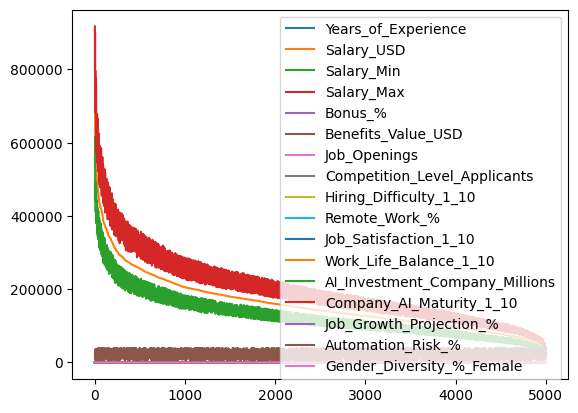

In [65]:
data.plot()

In [3]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 37 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Job_ID                          5000 non-null   str    
 1   Job_Title                       5000 non-null   str    
 2   AI_Specialization               5000 non-null   str    
 3   Industry                        5000 non-null   str    
 4   Company                         5000 non-null   str    
 5   Company_Size                    5000 non-null   str    
 6   Country                         5000 non-null   str    
 7   Continent                       5000 non-null   str    
 8   Education_Required              5000 non-null   str    
 9   Experience_Level                5000 non-null   str    
 10  Years_of_Experience             5000 non-null   int64  
 11  Salary_USD                      5000 non-null   float64
 12  Salary_Min                      5000 non-null

array([[<Axes: xlabel='Salary_USD', ylabel='Salary_USD'>,
        <Axes: xlabel='Salary_Min', ylabel='Salary_USD'>,
        <Axes: xlabel='Salary_Max', ylabel='Salary_USD'>],
       [<Axes: xlabel='Salary_USD', ylabel='Salary_Min'>,
        <Axes: xlabel='Salary_Min', ylabel='Salary_Min'>,
        <Axes: xlabel='Salary_Max', ylabel='Salary_Min'>],
       [<Axes: xlabel='Salary_USD', ylabel='Salary_Max'>,
        <Axes: xlabel='Salary_Min', ylabel='Salary_Max'>,
        <Axes: xlabel='Salary_Max', ylabel='Salary_Max'>]], dtype=object)

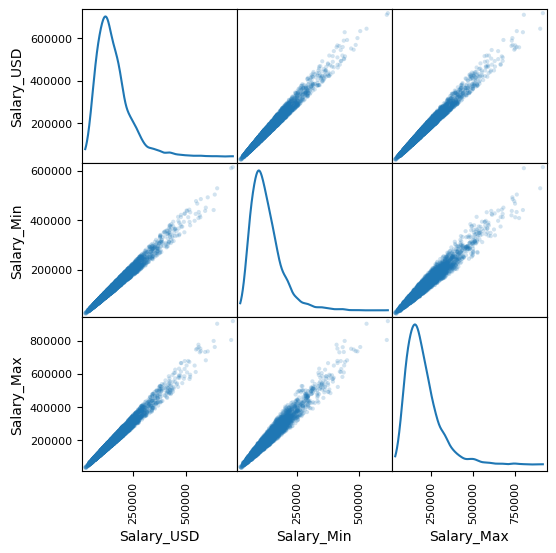

In [60]:
scatter_matrix(data_num, alpha=0.2, figsize=(6, 6), diagonal="kde")

Text(0.5, 1.0, 'Grafico de Densidad, de Salary_USD')

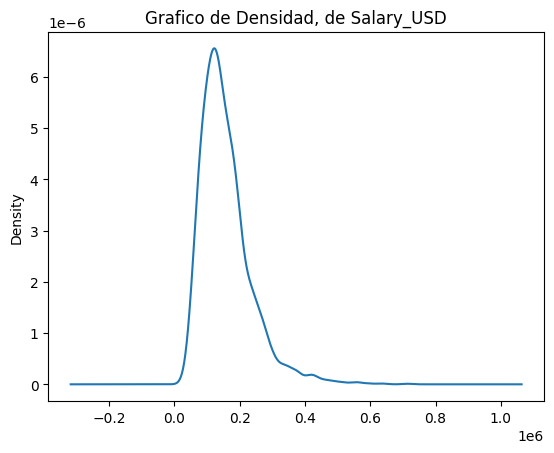

In [61]:
data["Salary_USD"].plot.kde()
plt.title("Grafico de Densidad, de Salary_USD")


Text(0.5, 1.0, 'Grafico de Caja')

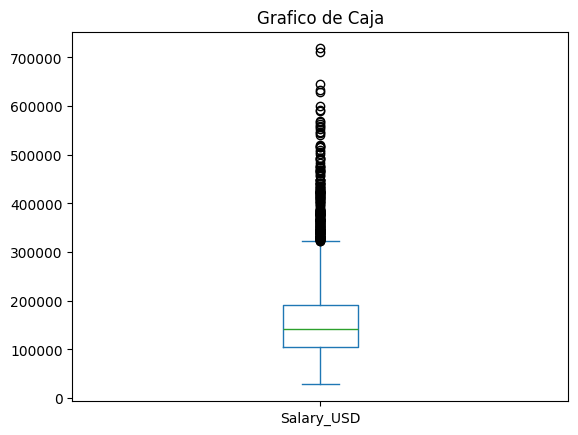

In [81]:
data["Salary_USD"].plot.box()
plt.title("Grafico de Caja")

Text(0, 0.5, 'f(x)')

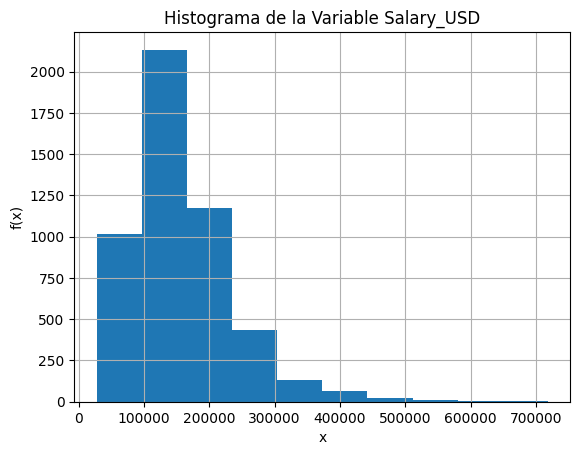

In [64]:
data["Salary_USD"].hist()
plt.title("Histograma de la Variable Salary_USD")
plt.xlabel("x")
plt.ylabel("f(x)")

# Prueba de Normalidad para la variable "Salary_USD"


### Para visualizar aun mas la calidad de nuestra Prueba, graficaremos el histograma de la variables "Salary_USD"

<Axes: >

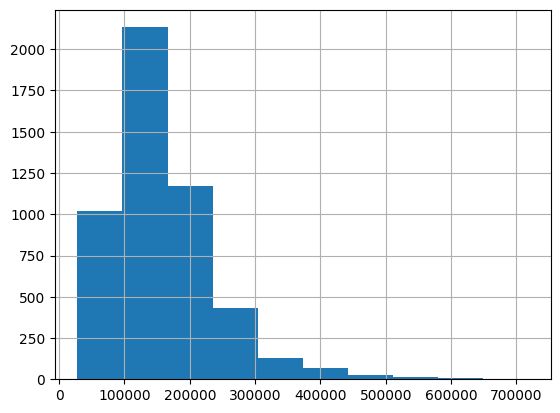

In [25]:
data["Salary_USD"].hist()

## Comenzaemos Aplicando la prueba de Shapiro Wilk

In [117]:
prueba_shapiro = stats.shapiro(data["Salary_USD"])
print(prueba_shapiro.statistic)

print(f'Valor del Estadistico: {prueba_shapiro.statistic} y Valor p: {prueba_shapiro.pvalue}\n')
p = prueba_shapiro.pvalue

alpha = 0.05
if p > alpha:
    print("La muestra parece ser una Distribucion Normal, gano la hipotesis Nula")
else:
    print("La muestra NO parece ser una Distribucion Normal, gano la hipotesis Alternativa")

0.88405160609447
Valor del Estadistico: 0.88405160609447 y Valor p: 9.857680184104484e-52

La muestra NO parece ser una Distribucion Normal, gano la hipotesis Alternativa


## Aplicaremos la Prueba de D'Agostino K^2 

In [31]:
res = stats.normaltest(data["Salary_USD"])
print(f'Valor del Estadistico: {res.statistic} y p-valor: {res.pvalue}\n')
p = res.pvalue

alpha = 0.05
if p > alpha:
    print("La muestra parece ser una Distribucion Normal, gano la hipotesis Nula")
else:
    print("La muestra NO parece ser una Distribucion Normal, gano la hipotesis Alternativa")

Valor del Estadistico: 1763.246778794155 y p-valor: 0.0

La muestra NO parece ser una Distribucion Normal, gano la hipotesis Alternativa


## Aplicaremos la prueba de Anderson

In [39]:
prueba_anderson = stats.anderson(data["Salary_USD"], dist='norm', method='interpolate')
print(f'Valor del Estadistico: {prueba_anderson.statistic} y p-valor :{prueba_anderson.pvalue}\n')
p = prueba_anderson.pvalue

alpha = 0.01
if p > alpha:
    print(f'La variables Salary_USD parecer ser una Distribucion Normal, gano la hipotesis NULA')
    
else:
    print(f'La variables Salary_USD NO  parecer ser una Distribucion Normal, gano la hipotesis Alternativa')


Valor del Estadistico: 114.80178611511019 y p-valor :0.01

La variables Salary_USD NO  parecer ser una Distribucion Normal, gano la hipotesis Alternativa


# Prueba de Normalidad para la variable "Years_of_Experience"
## Visualización de su Histograma y su Diagrama de caja

Text(0.5, 1.0, 'Histograma en la variable Years_of_Experience')

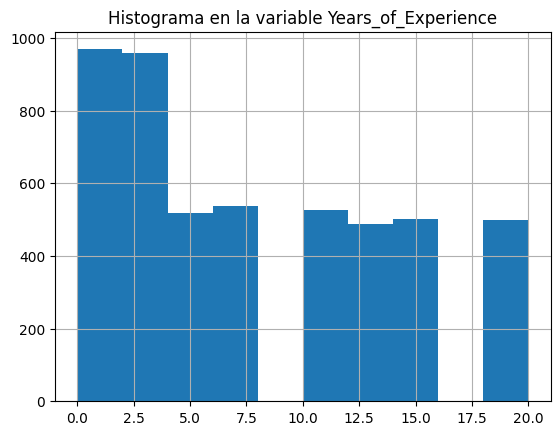

In [118]:
data["Years_of_Experience"].hist()
plt.title("Histograma en la variable Years_of_Experience")

Text(0.5, 1.0, 'Grafico de Caja en la variable Years_of_Experience')

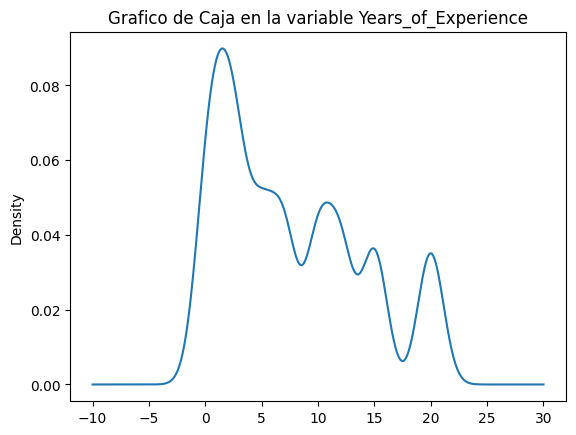

In [119]:

data["Years_of_Experience"].plot.kde()
plt.title("Grafico de Caja en la variable Years_of_Experience")

## Prueba de Normalidad de Shapiro Wilk

In [123]:
prueba_shapiro2 = stats.shapiro(data["Years_of_Experience"])
print(prueba_shapiro2.pvalue)
alpha = 0.05
if prueba_shapiro2.pvalue > alpha:
    print(f'Se distribuye como una normal, con error del {alpha}')
else:
    print(f'Se distribuye como una normal, con error del {alpha}')


4.436901453533759e-49
Se distribuye como una normal, con error del 0.05


## Prueba de Normalidad  D’Agostino’s K^2 Test 

In [125]:
prueba_agostino = stats.normaltest(data["Years_of_Experience"])
print(f'P-valor de {prueba_agostino.pvalue}\n')
print(f'Estadistico de: {prueba_agostino.statistic}\n')
alpha = 0.05
if prueba_agostino.pvalue >alpha:
    print(f'Se distribuye como una normal, con error del {alpha}')
else:
    print(f'NO se distribuye como una normal, con error del {alpha}')

P-valor de 1.4902456728213547e-140

Estadistico de: 643.9259440634245

NO se distribuye como una normal, con error del 0.05


## Prueba de Anderson-Darling Test 

In [127]:
prueba_anderson2 = stats.anderson(data["Years_of_Experience"],dist='norm',method='interpolate')
print(f'P-valor de : {prueba_anderson2.pvalue}\n')
print(f'P-valor de : {prueba_anderson2.statistic}\n')

alpha = 0.05
if prueba_anderson2.pvalue > alpha:
    print(f'Se distribuye como una normal, con error del {alpha}')
else:
    print(f'NO se distribuye como una normal, con error del {alpha}')

P-valor de : 0.01

P-valor de : 150.84039932660016

NO se distribuye como una normal, con error del 0.05
